# Proyek 5 — HCI dan Visualisasi Data: Dashboard Perilaku Belanja Online


In [1]:
import io, zipfile, urllib.request
import pandas as pd
import matplotlib.pyplot as plt

## 1. Unduh dataset UCI Online Shoppers Purchasing Intention

In [2]:
url="https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"
with urllib.request.urlopen(url) as r: raw=r.read()
with zipfile.ZipFile(io.BytesIO(raw)) as zf:
    csv_name=next(n for n in zf.namelist() if n.lower().endswith(".csv"))
    df=pd.read_csv(zf.open(csv_name))
print(df.shape); display(df.head()); print(df.dtypes)

(12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                       object
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                 object
Weekend                       bool
Revenue                       bool
dtype: object


## 2. KPI dan eksplorasi sederhana

Jumlah sesi: 12,330
Sesi dengan pembelian: 1,908
Conversion rate: 15.47%


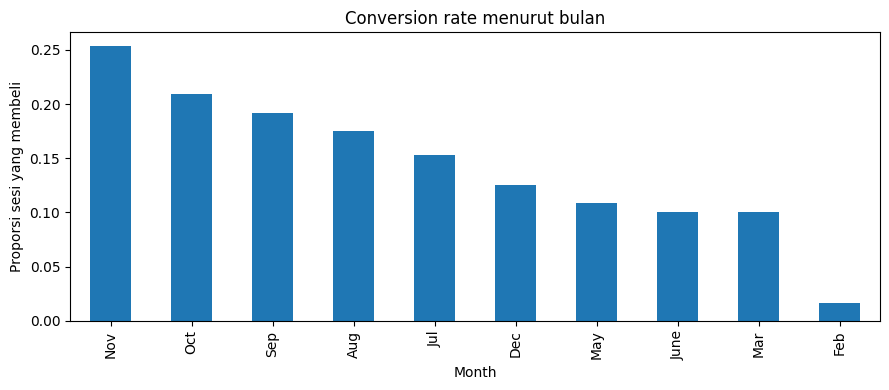

,sessions,conversion_rate
VisitorType,,
Returning_Visitor,10551,0.139323
New_Visitor,1694,0.249115
Other,85,0.188235


In [3]:
df["Revenue"] = df["Revenue"].astype(str).str.lower().map({"true":True,"false":False}).fillna(df["Revenue"])
if df["Revenue"].dtype != bool:
    df["Revenue"] = df["Revenue"].astype(bool)
conversion=float(df["Revenue"].mean())
print(f"Jumlah sesi: {len(df):,}")
print(f"Sesi dengan pembelian: {int(df['Revenue'].sum()):,}")
print(f"Conversion rate: {conversion:.2%}")
monthly=df.groupby("Month")["Revenue"].mean().sort_values(ascending=False) if "Month" in df.columns else pd.Series(dtype=float)
if not monthly.empty:
    plt.figure(figsize=(9,4)); monthly.plot(kind="bar"); plt.ylabel("Proporsi sesi yang membeli"); plt.title("Conversion rate menurut bulan"); plt.tight_layout(); plt.show()
if "VisitorType" in df.columns:
    display(df.groupby("VisitorType").agg(sessions=("Revenue","size"), conversion_rate=("Revenue","mean")).sort_values("sessions",ascending=False))

## 3. Ekspor dataset untuk dashboard

In [4]:
df.to_csv("online_shoppers_clean.csv",index=False)
print("Tersimpan: online_shoppers_clean.csv")
print("Unggah file CSV ini ke folder proyek lokal bersama app.py untuk menjalankan dashboard.")

Tersimpan: online_shoppers_clean.csv
Unggah file CSV ini ke folder proyek lokal bersama app.py untuk menjalankan dashboard.


## Rekomendasi HCI
Dashboard harus menampilkan KPI utama, filter yang jelas, label sumbu yang mudah dipahami, konsistensi warna, dan detail saat pengguna memilih kategori. Lakukan uji kegunaan sederhana kepada beberapa pengguna sebelum menyatakan dashboard mudah digunakan.